# Question 3 – Basic and Comparative Plots Using Matplotlib
## Scenario: Energy Consumption Analysis of a Data Centre (2024 vs 2025)

| Task | Description | Marks |
|---|---|---|
| a | Prepare and validate data; monthly differences and percentage changes | 10 |
| b | Comparative line plot with formatting, legends and annotations | 15 |
| c | Grouped and stacked bar charts | 15 |
| d | Histograms and box plots comparing both years | 15 |
| e | Visualization of monthly percentage changes | 10 |
| f | Customized figures: titles, axes, grids, legends, ticks, scales | 10 |
| g | Annual totals, average monthly consumption, peak and low-demand periods | 15 |
| h | Interpretation and demand-management strategies | 10 |

> **How to use:** run all cells from top to bottom; works in Jupyter and Google Colab.
> **Exam tip:** only the data lists in part (a) need changing if the numbers differ.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, MultipleLocator

pd.set_option("display.float_format", "{:,.2f}".format)

# Colours used for each year in every plot (consistent colours make comparisons easier)
C24, C25 = "#1f77b4", "#d62728"

## (a) Prepare and validate the dataset; monthly differences and % changes  *(10 marks)*

**Two kinds of change are calculated:**
1. **Year-over-year (YoY) change** for each month: `Difference = 2025 − 2024` and `% change = (2025 − 2024) / 2024 × 100`. This is what "monthly differences" between the two years means here.
2. **Month-over-month (MoM) change** within each year: `this month − previous month`. This shows the seasonal pattern.

In [2]:
months = ["Jan", "Feb", "Mar", "Apr", "May", "Jun", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
kwh_2024 = [4200, 3900, 4100, 4500, 5200, 6100, 6400, 6200, 5600, 4900, 4600, 4300]
kwh_2025 = [4500, 4100, 4300, 4700, 5500, 6400, 6800, 6600, 5900, 5200, 4800, 4600]

energy = pd.DataFrame({"Month": months, "Y2024": kwh_2024, "Y2025": kwh_2025})
energy

,Month,Y2024,Y2025
0,Jan,4200,4500
1,Feb,3900,4100
2,Mar,4100,4300
3,Apr,4500,4700
4,May,5200,5500
5,Jun,6100,6400
6,Jul,6400,6800
7,Aug,6200,6600
8,Sep,5600,5900
9,Oct,4900,5200


In [3]:
# ---- Validation checks ----
print("Shape:", energy.shape)
print("\nData types:\n", energy.dtypes, sep="")
print("\nMissing values:", energy.isnull().sum().sum())
print("Exactly 12 months?        :", len(energy) == 12)
print("Months unique and in order:", energy["Month"].tolist() == months and energy["Month"].is_unique)
print("All values numeric?       :", all(pd.api.types.is_numeric_dtype(energy[c]) for c in ["Y2024", "Y2025"]))
print("All values positive?      :", (energy[["Y2024", "Y2025"]] > 0).all().all())

# Make Month an ordered categorical so sorting/plots keep calendar order (not alphabetical)
energy["Month"] = pd.Categorical(energy["Month"], categories=months, ordered=True)

Shape: (12, 3)

Data types:
Month      str
Y2024    int64
Y2025    int64
dtype: object

Missing values: 0
Exactly 12 months?        : True
Months unique and in order: True
All values numeric?       : True
All values positive?      : True


In [4]:
# ---- Year-over-year differences ----
energy["Diff_kWh"] = energy["Y2025"] - energy["Y2024"]
energy["Pct_Change"] = (energy["Diff_kWh"] / energy["Y2024"] * 100).round(2)

# ---- Month-over-month changes within each year ----
energy["MoM_2024"] = energy["Y2024"].diff()                     # first month has no previous -> NaN
energy["MoM_2025"] = energy["Y2025"].diff()
energy["MoM_Pct_2024"] = (energy["Y2024"].pct_change() * 100).round(2)
energy["MoM_Pct_2025"] = (energy["Y2025"].pct_change() * 100).round(2)

energy

,Month,Y2024,Y2025,Diff_kWh,Pct_Change,MoM_2024,MoM_2025,MoM_Pct_2024,MoM_Pct_2025
0,Jan,4200,4500,300,7.14,NaN,NaN,NaN,NaN
1,Feb,3900,4100,200,5.13,-300.00,-400.00,-7.14,-8.89
2,Mar,4100,4300,200,4.88,200.00,200.00,5.13,4.88
3,Apr,4500,4700,200,4.44,400.00,400.00,9.76,9.30
4,May,5200,5500,300,5.77,700.00,800.00,15.56,17.02
5,Jun,6100,6400,300,4.92,900.00,900.00,17.31,16.36
6,Jul,6400,6800,400,6.25,300.00,400.00,4.92,6.25
7,Aug,6200,6600,400,6.45,-200.00,-200.00,-3.12,-2.94
8,Sep,5600,5900,300,5.36,-600.00,-700.00,-9.68,-10.61
9,Oct,4900,5200,300,6.12,-700.00,-700.00,-12.50,-11.86


In [5]:
print("Largest YoY increase (kWh):", energy.loc[energy["Diff_kWh"].idxmax(), "Month"], energy["Diff_kWh"].max(), "kWh")
print("Smallest YoY increase (kWh):", ", ".join(energy.loc[energy["Diff_kWh"] == energy["Diff_kWh"].min(), "Month"].astype(str)),
      energy["Diff_kWh"].min(), "kWh")
print("Largest YoY % increase :", energy.loc[energy["Pct_Change"].idxmax(), "Month"], f"{energy['Pct_Change'].max():.2f}%")
print("Smallest YoY % increase:", energy.loc[energy["Pct_Change"].idxmin(), "Month"], f"{energy['Pct_Change'].min():.2f}%")
print("Every month higher in 2025?", (energy["Diff_kWh"] > 0).all())
print(f"Average monthly YoY difference: {energy['Diff_kWh'].mean():.2f} kWh, average % change: {energy['Pct_Change'].mean():.2f}%")

Largest YoY increase (kWh): Jul 400 kWh
Smallest YoY increase (kWh): Feb, Mar, Apr, Nov 200 kWh
Largest YoY % increase : Jan 7.14%
Smallest YoY % increase: Nov 4.35%
Every month higher in 2025? True
Average monthly YoY difference: 283.33 kWh, average % change: 5.65%


## (b) Comparative line plot with formatting, legend and annotations  *(15 marks)*

A **line plot** is the right choice for data that changes over time (months). Both years go on the same axes for direct comparison. The shaded band shows the yearly increase, and annotations mark the peak and lowest months.

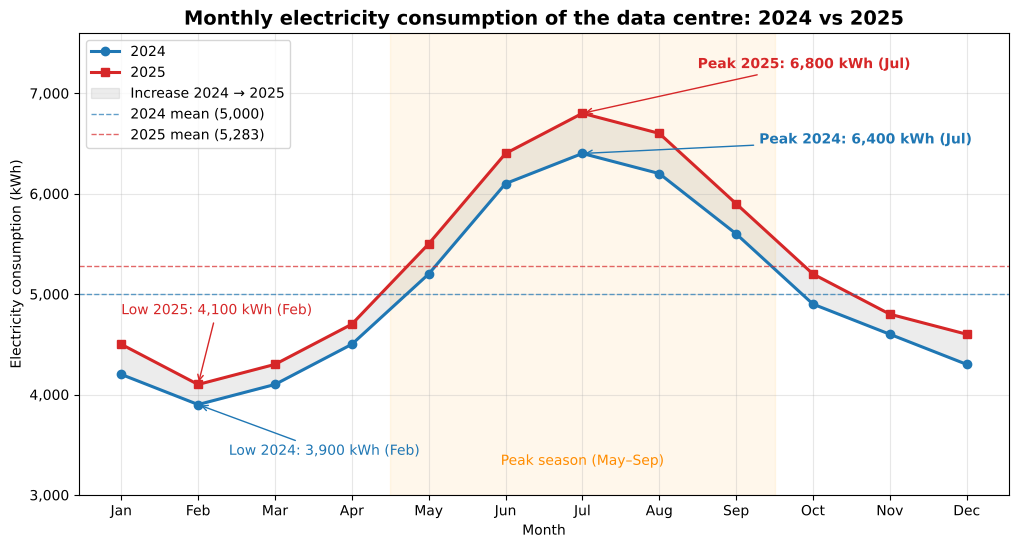

In [6]:
x = np.arange(len(months))
fig, ax = plt.subplots(figsize=(12, 6))

ax.plot(x, energy["Y2024"], marker="o", lw=2.2, color=C24, label="2024")
ax.plot(x, energy["Y2025"], marker="s", lw=2.2, color=C25, label="2025")
ax.fill_between(x, energy["Y2024"], energy["Y2025"], color="grey", alpha=0.15, label="Increase 2024 → 2025")

# Annotate the peak and lowest month of each year.
# xy = the point the arrow points to; xytext = where the label is written (chosen to avoid the lines)
label_pos = {"Y2024": {"peak": (8.3, 6500), "low": (1.4, 3400)},
             "Y2025": {"peak": (7.5, 7250), "low": (0.0, 4800)}}
for col, color in [("Y2024", C24), ("Y2025", C25)]:
    i_max, i_min = energy[col].idxmax(), energy[col].idxmin()
    ax.annotate(f"Peak {col[1:]}: {energy[col].max():,} kWh ({months[i_max]})",
                xy=(i_max, energy[col].max()), xytext=label_pos[col]["peak"],
                arrowprops=dict(arrowstyle="->", color=color), color=color, fontweight="bold")
    ax.annotate(f"Low {col[1:]}: {energy[col].min():,} kWh ({months[i_min]})",
                xy=(i_min, energy[col].min()), xytext=label_pos[col]["low"],
                arrowprops=dict(arrowstyle="->", color=color), color=color)

# Average lines
ax.axhline(energy["Y2024"].mean(), color=C24, ls="--", lw=1, alpha=0.7, label=f"2024 mean ({energy['Y2024'].mean():,.0f})")
ax.axhline(energy["Y2025"].mean(), color=C25, ls="--", lw=1, alpha=0.7, label=f"2025 mean ({energy['Y2025'].mean():,.0f})")

# Shade the peak season (months above the annual mean, see part g)
ax.axvspan(3.5, 8.5, color="orange", alpha=0.08)
ax.text(6, 3300, "Peak season (May–Sep)", ha="center", color="darkorange")

ax.set_xticks(x)
ax.set_xticklabels(months)
ax.set_ylim(3000, 7600)
ax.set_xlabel("Month")
ax.set_ylabel("Electricity consumption (kWh)")
ax.set_title("Monthly electricity consumption of the data centre: 2024 vs 2025", fontsize=14, fontweight="bold")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax.grid(alpha=0.3)
ax.legend(loc="upper left")
plt.show()

## (c) Grouped and stacked bar charts  *(15 marks)*

* **Grouped (side-by-side) bars** – compare 2024 and 2025 *month by month*.
* **Stacked bars** – each bar's total height is the *combined two-year* consumption of that month, split into the two years.
* **Annual / quarterly bars** – compare the *annual* (and quarterly) totals directly.

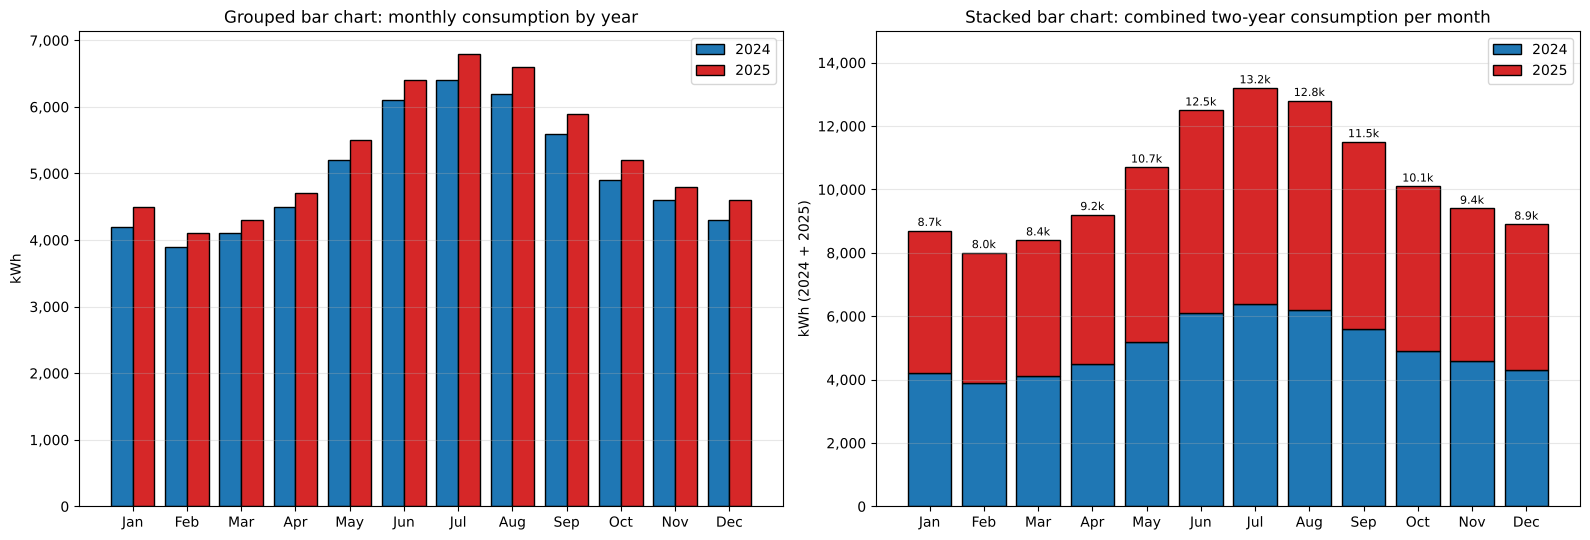

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))
w = 0.4

# Grouped bar chart
ax = axes[0]
b1 = ax.bar(x - w/2, energy["Y2024"], w, label="2024", color=C24, edgecolor="black")
b2 = ax.bar(x + w/2, energy["Y2025"], w, label="2025", color=C25, edgecolor="black")
ax.set_xticks(x)
ax.set_xticklabels(months)
ax.set_ylabel("kWh")
ax.set_title("Grouped bar chart: monthly consumption by year")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))

# Stacked bar chart
ax = axes[1]
ax.bar(x, energy["Y2024"], label="2024", color=C24, edgecolor="black")
ax.bar(x, energy["Y2025"], bottom=energy["Y2024"], label="2025", color=C25, edgecolor="black")
for xi, tot in zip(x, energy["Y2024"] + energy["Y2025"]):
    ax.text(xi, tot + 150, f"{tot/1000:.1f}k", ha="center", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels(months)
ax.set_ylabel("kWh (2024 + 2025)")
ax.set_ylim(0, 15000)
ax.set_title("Stacked bar chart: combined two-year consumption per month")
ax.legend()
ax.grid(axis="y", alpha=0.3)
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))

plt.tight_layout()
plt.show()

,Y2024,Y2025
Quarter,,
Q1,12200,12900
Q2,15800,16600
Q3,18200,19300
Q4,13800,14600


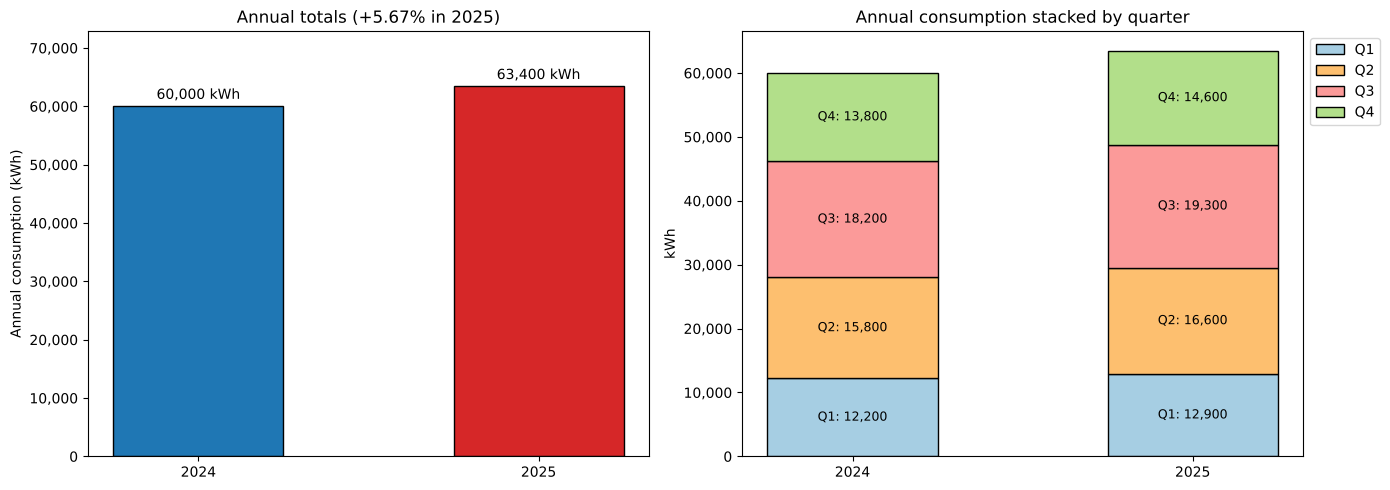

In [8]:
# Annual comparison: total per year, stacked by quarter
energy["Quarter"] = ["Q1"] * 3 + ["Q2"] * 3 + ["Q3"] * 3 + ["Q4"] * 3
quarterly = energy.groupby("Quarter")[["Y2024", "Y2025"]].sum()
display(quarterly)

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

# Annual totals side by side
ax = axes[0]
totals = energy[["Y2024", "Y2025"]].sum()
bars = ax.bar(["2024", "2025"], totals, color=[C24, C25], edgecolor="black", width=0.5)
ax.bar_label(bars, labels=[f"{v:,} kWh" for v in totals], padding=3)
ax.set_ylim(0, totals.max() * 1.15)
ax.set_ylabel("Annual consumption (kWh)")
ax.set_title(f"Annual totals (+{(totals['Y2025'] / totals['Y2024'] - 1) * 100:.2f}% in 2025)")
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))

# Annual totals stacked by quarter
ax = axes[1]
q_colors = ["#a6cee3", "#fdbf6f", "#fb9a99", "#b2df8a"]
bottom = np.zeros(2)
for q, c in zip(quarterly.index, q_colors):
    vals = quarterly.loc[q].values
    ax.bar(["2024", "2025"], vals, bottom=bottom, color=c, edgecolor="black", width=0.5, label=q)
    for i, v in enumerate(vals):
        ax.text(i, bottom[i] + v / 2, f"{q}: {v:,}", ha="center", va="center", fontsize=9)
    bottom += vals
ax.set_ylabel("kWh")
ax.set_title("Annual consumption stacked by quarter")
ax.legend(loc="upper left", bbox_to_anchor=(1, 1))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))

plt.tight_layout()
plt.show()

## (d) Histograms and box plots: comparing distributions  *(15 marks)*

* A **histogram** shows how often consumption falls into each range (bin). The **same bins** are used for both years so they can be compared fairly.
* A **box plot** shows the median (line), the quartiles (box = middle 50% of months), the whiskers and any outliers (points beyond 1.5 × IQR).

In [9]:
desc = energy[["Y2024", "Y2025"]].describe().T
desc["IQR"] = desc["75%"] - desc["25%"]
desc["Range"] = desc["max"] - desc["min"]
desc["CV_%"] = desc["std"] / desc["mean"] * 100
desc["Skewness"] = energy[["Y2024", "Y2025"]].skew()
display(desc)

,count,mean,std,min,25%,50%,75%,max,IQR,Range,CV_%,Skewness
Y2024,12.00,"5,000.00",883.18,"3,900.00","4,275.00","4,750.00","5,725.00","6,400.00","1,450.00","2,500.00",17.66,0.46
Y2025,12.00,"5,283.33",940.82,"4,100.00","4,575.00","5,000.00","6,025.00","6,800.00","1,450.00","2,700.00",17.81,0.48


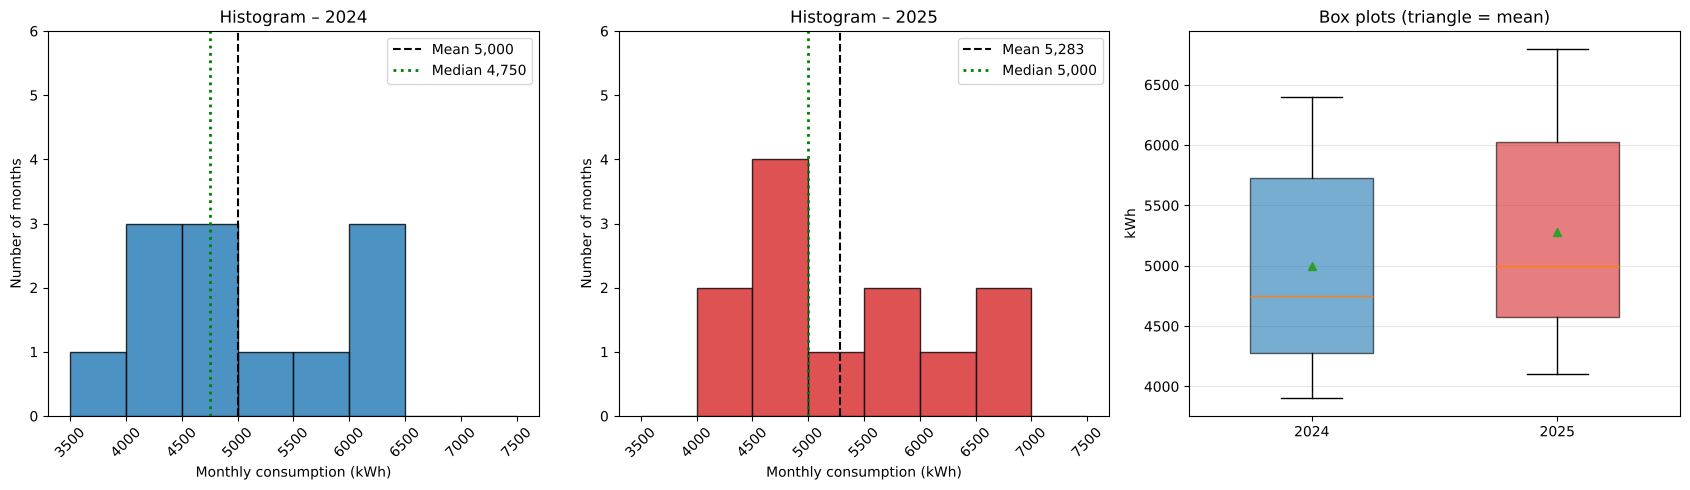

In [10]:
bins = np.arange(3500, 7501, 500)     # identical bins for both years: 3500-4000, 4000-4500, ...
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# Side-by-side histograms
for ax, col, color in [(axes[0], "Y2024", C24), (axes[1], "Y2025", C25)]:
    ax.hist(energy[col], bins=bins, color=color, edgecolor="black", alpha=0.8)
    ax.axvline(energy[col].mean(), color="black", ls="--", label=f"Mean {energy[col].mean():,.0f}")
    ax.axvline(energy[col].median(), color="green", ls=":", lw=2, label=f"Median {energy[col].median():,.0f}")
    ax.set_title(f"Histogram – {col[1:]}")
    ax.set_xlabel("Monthly consumption (kWh)")
    ax.set_ylabel("Number of months")
    ax.set_xticks(bins)
    ax.tick_params(axis="x", rotation=45)
    ax.yaxis.set_major_locator(MultipleLocator(1))
    ax.set_ylim(0, 6)                    # headroom so the legend does not cover the bars
    ax.legend(loc="upper right")

# Box plots side by side
ax = axes[2]
bp = ax.boxplot([energy["Y2024"], energy["Y2025"]], patch_artist=True, showmeans=True, widths=0.5)
for patch, c in zip(bp["boxes"], [C24, C25]):
    patch.set_facecolor(c)
    patch.set_alpha(0.6)
ax.set_xticks([1, 2])
ax.set_xticklabels(["2024", "2025"])
ax.set_ylabel("kWh")
ax.set_title("Box plots (triangle = mean)")
ax.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

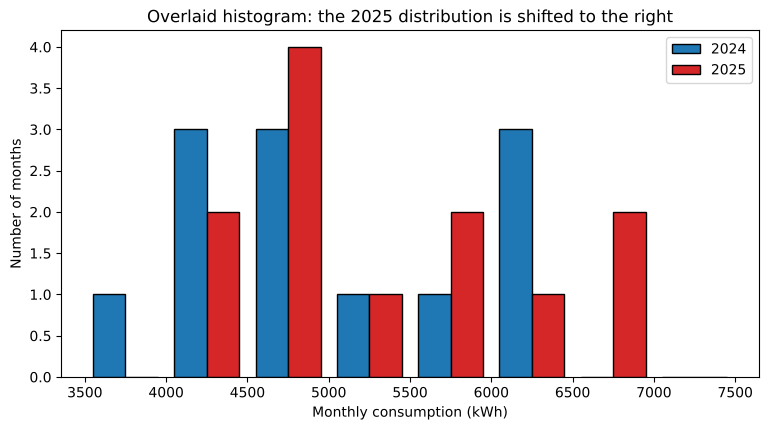

In [11]:
# Overlaid histogram: both years on the same axes
plt.figure(figsize=(9, 4.5))
plt.hist([energy["Y2024"], energy["Y2025"]], bins=bins, color=[C24, C25], edgecolor="black", label=["2024", "2025"])
plt.xlabel("Monthly consumption (kWh)")
plt.ylabel("Number of months")
plt.title("Overlaid histogram: the 2025 distribution is shifted to the right")
plt.xticks(bins)
plt.legend()
plt.show()

In [12]:
# Outlier check with the 1.5 x IQR rule
for col in ["Y2024", "Y2025"]:
    q1, q3 = energy[col].quantile([0.25, 0.75])
    iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    out = energy.loc[(energy[col] < lo) | (energy[col] > hi), "Month"].tolist()
    print(f"{col[1:]}: Q1={q1:,.0f}, Q3={q3:,.0f}, IQR={iqr:,.0f}, fences=[{lo:,.0f}, {hi:,.0f}] -> outliers: {out if out else 'none'}")

2024: Q1=4,275, Q3=5,725, IQR=1,450, fences=[2,100, 7,900] -> outliers: none
2025: Q1=4,575, Q3=6,025, IQR=1,450, fences=[2,400, 8,200] -> outliers: none


**Distribution comparison:**
* **Shape:** the two years look very similar. Most months fall between about 4,000 and 5,000 kWh (the cooler months), and a separate group of summer months lies above 5,500–6,000 kWh. This seasonal pattern makes both distributions **mildly right-skewed** (skewness ≈ 0.46 and 0.48; mean > median in both years).
* **Location:** the 2025 distribution is **shifted upward**. The mean rises from 5,000 to 5,283 kWh (+283) and the median from 4,750 to 5,000 kWh. Minimum, quartiles and maximum are all higher.
* **Spread:** almost unchanged. The IQR is identical (1,450 kWh) and the CV is about the same (17.7% vs 17.8%). The SD (883 → 941) and range (2,500 → 2,700) grow slightly because the peak rose more in absolute terms.
* **Outliers:** none in either year under the 1.5 × IQR rule, so the summer peak is a normal seasonal pattern, not an anomaly.

## (e) Visualizing monthly percentage changes  *(10 marks)*

A **bar chart** suits percentage changes: bar height is the % change, a horizontal reference line marks 0 %, and labels give exact values. Positive and negative changes would be shown in different colours (here all are positive). A second panel shows month-over-month % change (the seasonal swing) for each year.

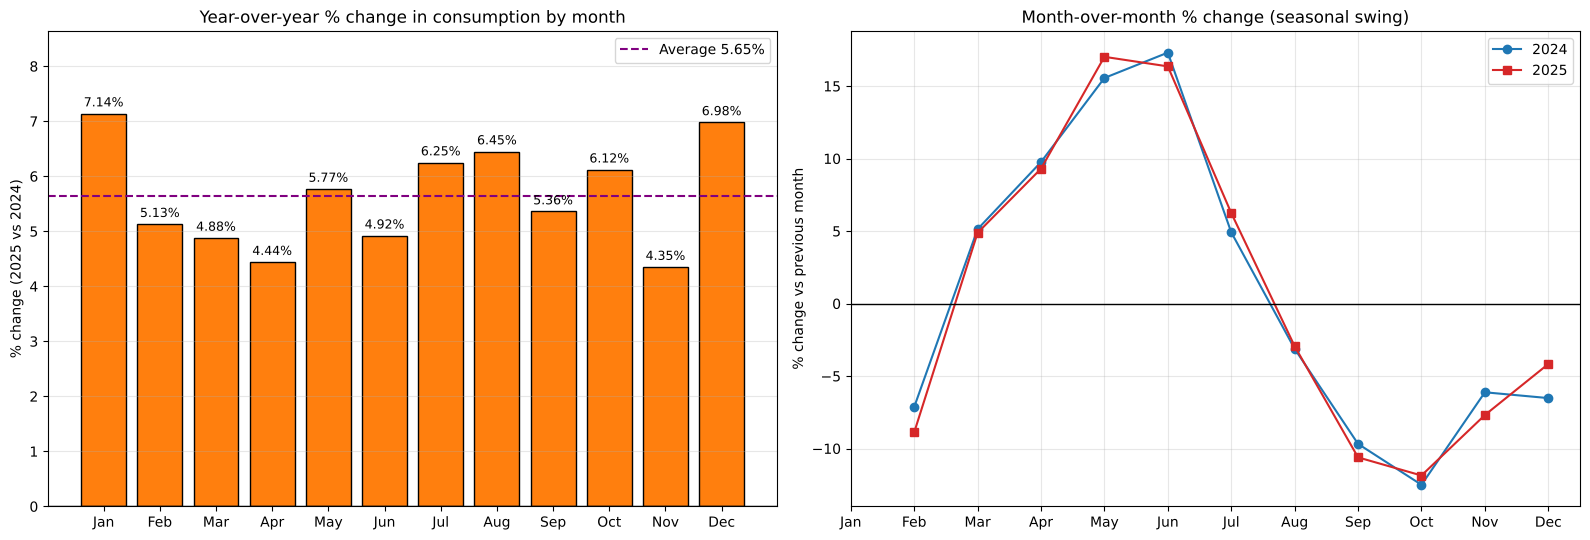

In [13]:
fig, axes = plt.subplots(1, 2, figsize=(16, 5.5))

ax = axes[0]
pct = energy["Pct_Change"]
colors = ["#2ca02c" if v < 0 else "#ff7f0e" for v in pct]
bars = ax.bar(months, pct, color=colors, edgecolor="black")
ax.bar_label(bars, labels=[f"{v:.2f}%" for v in pct], padding=3, fontsize=9)
ax.axhline(0, color="black", lw=1)
ax.axhline(pct.mean(), color="purple", ls="--", label=f"Average {pct.mean():.2f}%")
ax.set_ylim(0, pct.max() + 1.5)
ax.set_ylabel("% change (2025 vs 2024)")
ax.set_title("Year-over-year % change in consumption by month")
ax.legend()
ax.grid(axis="y", alpha=0.3)

ax = axes[1]
ax.plot(x, energy["MoM_Pct_2024"], marker="o", color=C24, label="2024")   # Jan is NaN (no previous month)
ax.plot(x, energy["MoM_Pct_2025"], marker="s", color=C25, label="2025")
ax.axhline(0, color="black", lw=1)
ax.set_xticks(x)
ax.set_xticklabels(months)
ax.set_ylabel("% change vs previous month")
ax.set_title("Month-over-month % change (seasonal swing)")
ax.legend()
ax.grid(alpha=0.3)

plt.tight_layout()
plt.show()

## (f) Fully customized figure: titles, axes, grids, legends, ticks and scales  *(10 marks)*

This figure shows the customization options one by one:
* **Title and subtitle**, **axis labels** with units.
* **Major and minor ticks** (`MultipleLocator`) and a **thousands-separator formatter**.
* **Major and minor grid lines** with different styles.
* **Legend** placed outside the data area.
* **Twin y-axis (`twinx`)** for a second scale (% change), since kWh and % have different units.
* **Appropriate scale:** the y-axis starts at 0, which shows the true size of the difference, while the inset uses a zoomed scale to show detail.

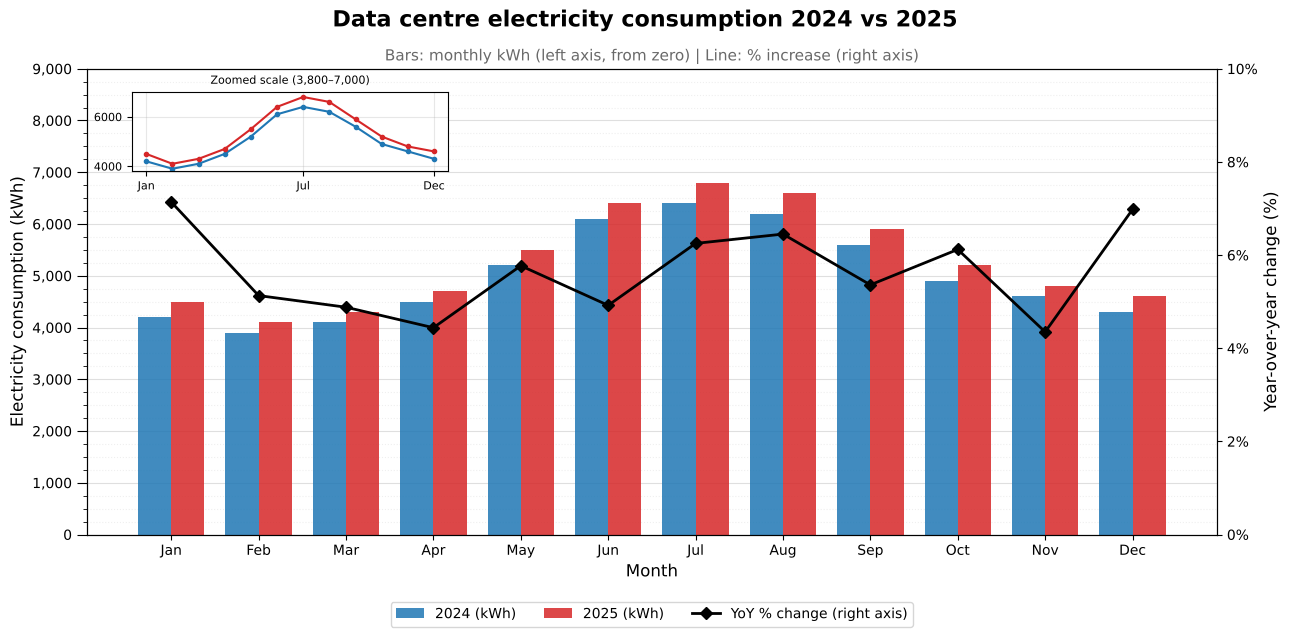

In [14]:
fig, ax = plt.subplots(figsize=(13, 6.5))

w = 0.38
ax.bar(x - w/2, energy["Y2024"], w, color=C24, alpha=0.85, label="2024 (kWh)")
ax.bar(x + w/2, energy["Y2025"], w, color=C25, alpha=0.85, label="2025 (kWh)")

# Axis scale and ticks for kWh
ax.set_ylim(0, 9000)
ax.yaxis.set_major_locator(MultipleLocator(1000))
ax.yaxis.set_minor_locator(MultipleLocator(250))
ax.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:,.0f}"))
ax.set_xticks(x)
ax.set_xticklabels(months, fontsize=10)
ax.tick_params(axis="y", which="major", length=7)
ax.tick_params(axis="y", which="minor", length=3)

# Grids
ax.grid(axis="y", which="major", ls="-", alpha=0.4)
ax.grid(axis="y", which="minor", ls=":", alpha=0.2)
ax.set_axisbelow(True)

ax.set_xlabel("Month", fontsize=12)
ax.set_ylabel("Electricity consumption (kWh)", fontsize=12)

# Second y-axis for percentage change
ax2 = ax.twinx()
ax2.plot(x, energy["Pct_Change"], color="black", marker="D", lw=2, label="YoY % change (right axis)")
ax2.set_ylim(0, 10)
ax2.set_ylabel("Year-over-year change (%)", fontsize=12)
ax2.yaxis.set_major_formatter(FuncFormatter(lambda v, p: f"{v:.0f}%"))

# Combined legend from both axes, placed outside the plot area
h1, l1 = ax.get_legend_handles_labels()
h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper center", bbox_to_anchor=(0.5, -0.13), ncol=3, frameon=True)

fig.suptitle("Data centre electricity consumption 2024 vs 2025", fontsize=16, fontweight="bold")
ax.set_title("Bars: monthly kWh (left axis, from zero) | Line: % increase (right axis)", fontsize=11, color="dimgray")

# Inset with a zoomed scale to show the gap between the years more clearly
inset = ax.inset_axes([0.04, 0.78, 0.28, 0.17])
inset.plot(x, energy["Y2024"], color=C24, marker=".")
inset.plot(x, energy["Y2025"], color=C25, marker=".")
inset.set_ylim(3800, 7000)
inset.set_xticks([0, 6, 11])
inset.set_xticklabels(["Jan", "Jul", "Dec"], fontsize=8)
inset.tick_params(labelsize=8)
inset.set_title("Zoomed scale (3,800–7,000)", fontsize=8)
inset.grid(alpha=0.3)

plt.tight_layout()
plt.show()

**Choosing scales:** for bar charts the axis should **start at zero**, otherwise bar heights exaggerate the differences. A zoomed axis (inset) or a line chart is acceptable when the goal is to see detail. A **log scale** is only useful when values span several orders of magnitude, which is not the case here: all values are between 3,900 and 6,800, less than a factor of 2.

## (g) Annual totals, average monthly consumption, peak and low-demand periods  *(15 marks)*

* **Peak / low month** = the month with the maximum / minimum consumption.
* **Peak-demand period** = months whose consumption is **above the annual mean**. **Low-demand period** = months **at or below the 25th percentile**. The season-level view (quarters) is also given.

In [15]:
summary = pd.DataFrame(index=["2024", "2025"])
for yr, col in [("2024", "Y2024"), ("2025", "Y2025")]:
    s = energy.set_index("Month")[col]
    summary.loc[yr, "Annual total (kWh)"] = s.sum()
    summary.loc[yr, "Avg monthly (kWh)"] = s.mean()
    summary.loc[yr, "Median monthly (kWh)"] = s.median()
    summary.loc[yr, "Peak month"] = f"{s.idxmax()} ({s.max():,})"
    summary.loc[yr, "Lowest month"] = f"{s.idxmin()} ({s.min():,})"
    summary.loc[yr, "Peak / low ratio"] = round(s.max() / s.min(), 2)
display(summary)

t24, t25 = energy["Y2024"].sum(), energy["Y2025"].sum()
print(f"Annual increase: {t25 - t24:,} kWh ({(t25 - t24) / t24 * 100:.2f}%)")
print(f"Average monthly consumption increased from {t24 / 12:,.2f} to {t25 / 12:,.2f} kWh")

,Annual total (kWh),Avg monthly (kWh),Median monthly (kWh),Peak month,Lowest month,Peak / low ratio
2024,"60,000.00","5,000.00","4,750.00","Jul (6,400)","Feb (3,900)",1.64
2025,"63,400.00","5,283.33","5,000.00","Jul (6,800)","Feb (4,100)",1.66


Annual increase: 3,400 kWh (5.67%)
Average monthly consumption increased from 5,000.00 to 5,283.33 kWh


In [16]:
for col in ["Y2024", "Y2025"]:
    s = energy.set_index("Month")[col]
    peak = s[s > s.mean()]
    low = s[s <= s.quantile(0.25)]
    print(f"{col[1:]}  mean = {s.mean():,.2f} kWh")
    print(f"   Peak-demand months (above mean)    : {', '.join(peak.index.astype(str))}  "
          f"-> {peak.sum():,} kWh = {peak.sum() / s.sum() * 100:.1f}% of annual use in {len(peak)} months")
    print(f"   Low-demand months (<= 25th pct {s.quantile(0.25):,.0f}): {', '.join(low.index.astype(str))}")

print("\nQuarterly share of annual consumption (%):")
display((quarterly / quarterly.sum() * 100).round(2))

2024  mean = 5,000.00 kWh
   Peak-demand months (above mean)    : May, Jun, Jul, Aug, Sep  -> 29,500 kWh = 49.2% of annual use in 5 months
   Low-demand months (<= 25th pct 4,275): Jan, Feb, Mar
2025  mean = 5,283.33 kWh
   Peak-demand months (above mean)    : May, Jun, Jul, Aug, Sep  -> 31,200 kWh = 49.2% of annual use in 5 months
   Low-demand months (<= 25th pct 4,575): Jan, Feb, Mar

Quarterly share of annual consumption (%):


,Y2024,Y2025
Quarter,,
Q1,20.33,20.35
Q2,26.33,26.18
Q3,30.33,30.44
Q4,23.00,23.03


## (h) Interpretation and energy-demand management strategies  *(10 marks)*

In [17]:
# Simple projection for 2026, assuming the same growth rate continues (for planning only)
growth = t25 / t24
print(f"Growth factor 2024 -> 2025: {growth:.4f}")
print(f"Projected 2026 annual consumption: {t25 * growth:,.0f} kWh")
print(f"Projected 2026 July peak         : {energy['Y2025'].max() * growth:,.0f} kWh")
print(f"Max month-over-month rise        : {energy[['MoM_Pct_2024', 'MoM_Pct_2025']].max().max():.2f}% "
      f"(May/Jun ramp-up), max fall: {energy[['MoM_Pct_2024', 'MoM_Pct_2025']].min().min():.2f}% (Oct)")

Growth factor 2024 -> 2025: 1.0567
Projected 2026 annual consumption: 66,993 kWh
Projected 2026 July peak         : 7,185 kWh
Max month-over-month rise        : 17.31% (May/Jun ramp-up), max fall: -12.50% (Oct)


### Interpretation of the findings

1. **Consumption is growing.** Annual consumption rose from **60,000 kWh to 63,400 kWh (+3,400 kWh, +5.67%)**, and the average month went from **5,000 to 5,283 kWh**.
2. **The increase is uniform and persistent.** **Every** month of 2025 is higher than the same month of 2024, by 200–400 kWh (**4.35%–7.14%**, average 5.65%). This points to a structural rise in IT load (more servers or workloads), not a one-off event.
3. **Strong seasonality.** The monthly pattern repeats almost exactly in both years:
   * **Peak:** July (6,400 → 6,800 kWh). The peak-demand period is **May–Sep**, the months above the annual mean, which use **49.2% of the year's energy in 5 months**. Q3 alone uses about 30%.
   * **Low:** February (3,900 → 4,100 kWh). The low-demand period is **Jan–Mar** (Q1 ≈ 20%).
   * The peak month uses about **1.65 times** as much as the lowest month. The steepest rises happen in **May and June (+15% to +17% per month)** and the steepest falls in **Sep–Oct (about −10% to −12.5%)**.
   * This is typical of **cooling load**: the hotter the weather, the more energy the cooling systems need.
4. **The seasonal shape did not change.** Quarterly shares are the same to within 0.15 percentage points. Growth affected all months proportionally.
5. **Outlook:** if growth continues at the same rate, 2026 would need about **67,000 kWh** with a July peak of about **7,190 kWh**.

### Recommended energy-demand management strategies

| Area | Strategy |
|---|---|
| **Cooling efficiency (summer peak)** | Hot/cold-aisle containment; raise supply-air temperature within recommended limits; use free-air/economizer cooling in Oct–Apr; service chillers and CRAC units in **April**, before the May ramp-up. |
| **Load shifting** | Move flexible batch jobs (backups, analytics, model training) to night hours and to the low-demand months where possible; use time-of-use tariffs. |
| **Controlling base growth** | Server virtualization and consolidation, switching off idle ("zombie") servers, and energy-efficient hardware refreshes to slow the +5.7% yearly growth. |
| **Renewables and contracts** | Rooftop or contracted solar, whose output is highest in summer and matches the peak; negotiate a demand-response agreement with the utility for May–Sep. |
| **Capacity planning** | Plan power and cooling capacity for a summer peak of about 7,200 kWh/month in 2026 with a safety margin. |
| **Monitoring** | Track **PUE** (Power Usage Effectiveness) and monthly kWh on a dashboard, with alerts when a month exceeds the same month of the previous year by more than ~5%. |

*Limitation:* only two years of monthly totals are available, so the growth rate and projection are rough. Temperature and IT-load data would be needed to confirm that cooling drives the summer peak.